# Dimensionality Reduction

Dimensionality Reduction is an unsupervised learning technique used to reduce the number of features (dimensions) in a dataset while preserving as much relevant information as possible.

High-dimensional datasets may contain redundant, irrelevant, or highly correlated features, making analysis and modelling computationally expensive.

Dimensionality reduction transforms data into a lower-dimensional representation that is easier to analyze, visualize, and process.

## How It Works
1. Analyzes the features and relationships within the dataset.
2. Identifies important patterns, structures, or sources of variation.
3. Transforms the original features into a smaller set of dimensions.
4. Retains important information while reducing complexity.
5. Produces a lower-dimensional representation of the original data.

## Main Approaches

**1. Feature Selection**
Selects a subset of the original features without transforming them.

**2. Feature Extraction**
Creates new features by transforming or combining the original features.

## Key Concepts
- **Dimensionality:** Number of features or variables in a dataset.
- **Feature Extraction:** Creating new representations from existing features.
- **Variance:** Measures how much information or variation exists in the data.
- **Principal Components:** New uncorrelated variables representing the data.
- **Manifold Learning:** Identifying lower-dimensional structures within high-dimensional data.
- **Information Loss:** Information lost when reducing the number of dimensions.

## Common Algorithms
- **PCA (Principal Component Analysis):** Reduces dimensions by preserving maximum variance.
- **ICA (Independent Component Analysis):** Separates data into statistically independent components.
- **t-SNE (t-Distributed Stochastic Neighbor Embedding):** Preserves local similarities for visualization.
- **Isomap (Isometric Mapping):** Preserves nonlinear geometric relationships using manifold learning.
- **NMF (Non-negative Matrix Factorization):** Decomposes non-negative data into lower-dimensional matrices, identifying underlying patterns and parts-based representations

## Advantages
- Reduces computational complexity.
- Helps eliminate redundant features.
- Supports data visualization.
- Can reduce noise and multicollinearity.
- Improves efficiency in downstream modelling.

## Limitations
- May result in information loss.
- Transformed features can be difficult to interpret.
- Some methods are computationally expensive.
- Different algorithms preserve different aspects of the data.

## Applications
- Image processing and recognition.
- Data visualization.
- Pattern recognition.
- Signal processing.
- Genomics and bioinformatics.
- Machine learning preprocessing.

In [232]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [233]:
import matplotlib as mpl

mpl.rcParams['font.enable_last_resort'] = False
mpl.rcParams['font.family'] = 'DejaVu Sans'
mpl.rcParams['text.usetex'] = False
mpl.rcParams['axes.unicode_minus'] = False

## PCA 

### digits dataset

In [234]:
# load dataset
digits = load_digits()

X = pd.DataFrame(digits.data,columns=digits.feature_names)

y = digits.target
print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
X.head()

Dataset shape: (1797, 64)
Target shape: (1797,)


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0


In [235]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1797 entries, 0 to 1796
Data columns (total 64 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pixel_0_0  1797 non-null   float64
 1   pixel_0_1  1797 non-null   float64
 2   pixel_0_2  1797 non-null   float64
 3   pixel_0_3  1797 non-null   float64
 4   pixel_0_4  1797 non-null   float64
 5   pixel_0_5  1797 non-null   float64
 6   pixel_0_6  1797 non-null   float64
 7   pixel_0_7  1797 non-null   float64
 8   pixel_1_0  1797 non-null   float64
 9   pixel_1_1  1797 non-null   float64
 10  pixel_1_2  1797 non-null   float64
 11  pixel_1_3  1797 non-null   float64
 12  pixel_1_4  1797 non-null   float64
 13  pixel_1_5  1797 non-null   float64
 14  pixel_1_6  1797 non-null   float64
 15  pixel_1_7  1797 non-null   float64
 16  pixel_2_0  1797 non-null   float64
 17  pixel_2_1  1797 non-null   float64
 18  pixel_2_2  1797 non-null   float64
 19  pixel_2_3  1797 non-null   float64
 20  pixel_2_

In [236]:
X.describe()

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
count,1797.0,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,...,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000
mean,0.0,0.303840,5.204786,11.835838,11.848080,5.781859,1.362270,0.129661,0.005565,1.993879,...,3.725097,0.206455,0.000556,0.279354,5.557596,12.089037,11.809126,6.764051,2.067891,0.364496
std,0.0,0.907192,4.754826,4.248842,4.287388,5.666418,3.325775,1.037383,0.094222,3.196160,...,4.919406,0.984401,0.023590,0.934302,5.103019,4.374694,4.933947,5.900623,4.090548,1.860122
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,1.000000,10.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,11.000000,10.000000,0.000000,0.000000,0.000000
50%,0.0,0.000000,4.000000,13.000000,13.000000,4.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,4.000000,13.000000,14.000000,6.000000,0.000000,0.000000
75%,0.0,0.000000,9.000000,15.000000,15.000000,11.000000,0.000000,0.000000,0.000000,3.000000,...,7.000000,0.000000,0.000000,0.000000,10.000000,16.000000,16.000000,12.000000,2.000000,0.000000
max,0.0,8.000000,16.000000,16.000000,16.000000,16.000000,16.000000,15.000000,2.000000,16.000000,...,16.000000,13.000000,1.000000,9.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000


In [237]:
X.isnull().sum().sum()

np.int64(0)

In [238]:
# target distribution
digit_counts = pd.Series(y).value_counts().sort_index()

digit_counts

0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64

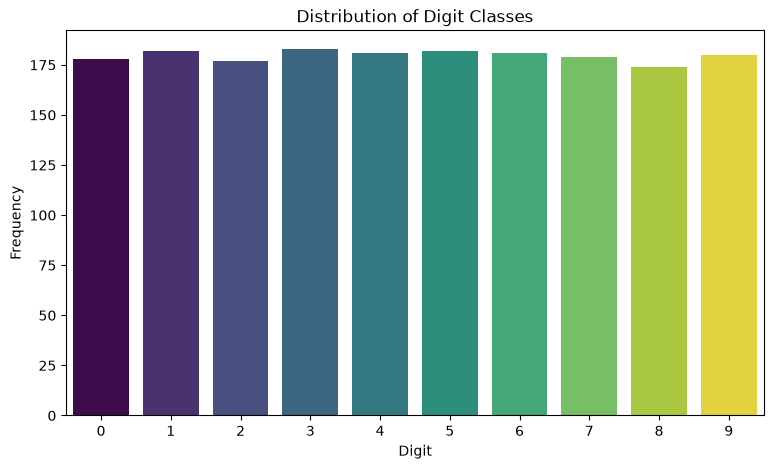

In [239]:
plt.figure(figsize=(9, 5))

sns.countplot(x=y,hue=y,palette='viridis',legend=False)

plt.title('Distribution of Digit Classes')
plt.xlabel('Digit')
plt.ylabel('Frequency')
plt.show()

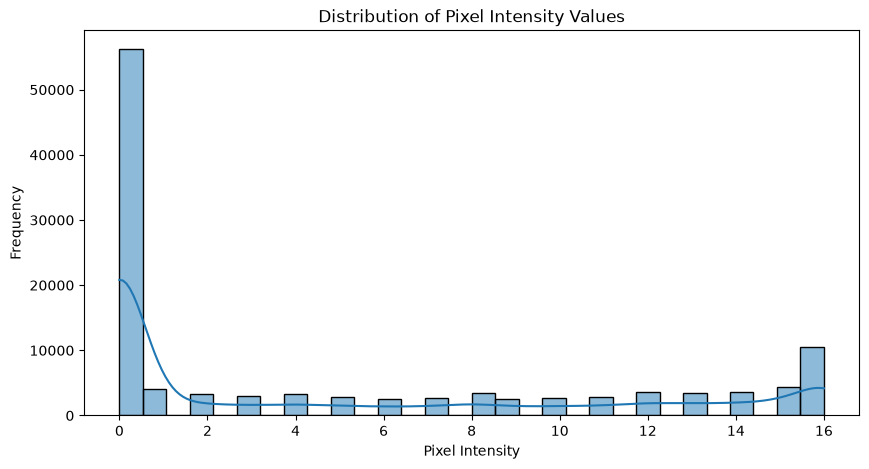

In [240]:
# feature distribution
plt.figure(figsize=(10, 5))

sns.histplot(X.values.flatten(),bins=30,kde=True)

plt.title('Distribution of Pixel Intensity Values')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.show()

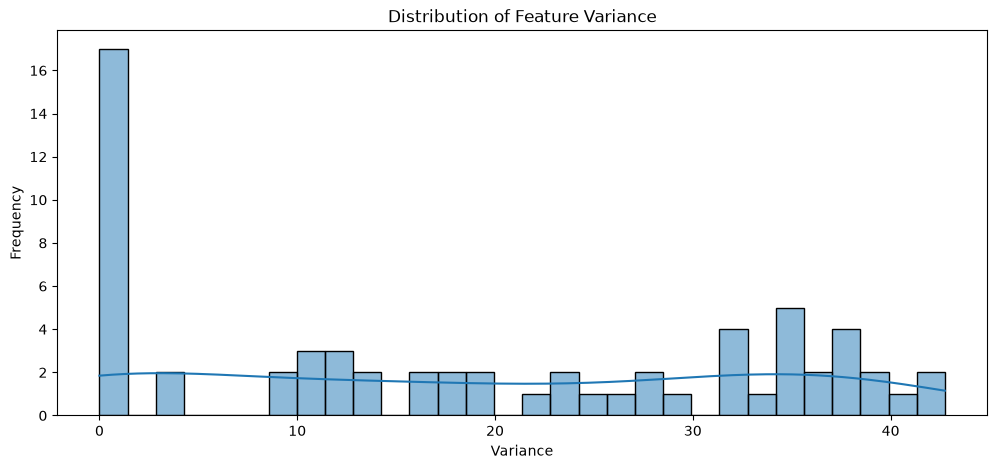

In [241]:
# feature variance
feature_variance = X.var()

plt.figure(figsize=(12, 5))

sns.histplot(feature_variance, bins=30, kde=True)

plt.title('Distribution of Feature Variance')
plt.xlabel('Variance')
plt.ylabel('Frequency')
plt.show()

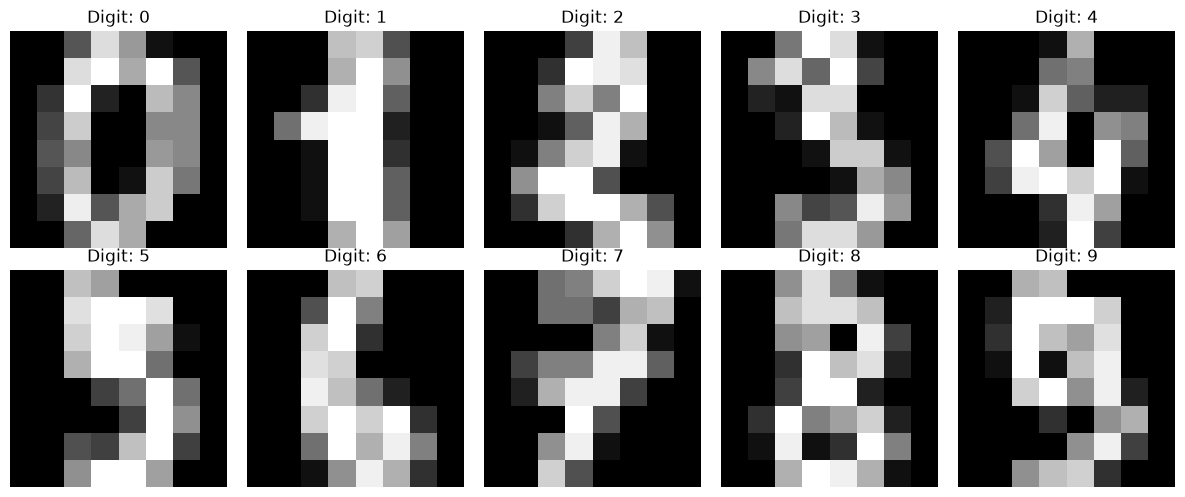

In [242]:
# sample handwritten digits
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flatten()):
    ax.imshow(digits.images[i], cmap='gray')
    ax.set_title(f'Digit: {y[i]}')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [243]:
# unique values and feature ranges 
print("Minimum Pixel Value:", X.min().min())
print("Maximum Pixel Value:", X.max().max())

print("\nUnique Target Classes:", np.unique(y))
print("Number of Features:", X.shape[1])

Minimum Pixel Value: 0.0
Maximum Pixel Value: 16.0

Unique Target Classes: [0 1 2 3 4 5 6 7 8 9]
Number of Features: 64


In [244]:
# preprocessing
X = digits.data
y = digits.target
X.shape

(1797, 64)

In [245]:
# scaling
scaler = StandardScaler()

X_scaled_features = scaler.fit_transform(X)
print("Scaled data shape:", X_scaled_features.shape)
print("Feature means:", np.round(X_scaled_features.mean(axis=0)[:5], 4))
print("Feature standard deviations:", np.round(X_scaled_features.std(axis=0)[:5], 4))

Scaled data shape: (1797, 64)
Feature means: [ 0. -0. -0. -0.  0.]
Feature standard deviations: [0. 1. 1. 1. 1.]


In [246]:
# PCA modelling
pca = PCA()

X_p = pca.fit_transform(X_scaled_features)
print("Original Shape:", X.shape)
print("Transformed Shape:", X_p.shape)

Original Shape: (1797, 64)
Transformed Shape: (1797, 64)


In [247]:
explained_variance = pca.explained_variance_ratio_

print("Explained Variance Ratio:", explained_variance)
print("Total Explained Variance:", explained_variance.sum())

Explained Variance Ratio: [1.20339161e-01 9.56105440e-02 8.44441489e-02 6.49840791e-02
 4.86015488e-02 4.21411987e-02 3.94208280e-02 3.38938092e-02
 2.99822101e-02 2.93200255e-02 2.78180546e-02 2.57705509e-02
 2.27530332e-02 2.22717974e-02 2.16522943e-02 1.91416661e-02
 1.77554709e-02 1.63806927e-02 1.59646017e-02 1.48919119e-02
 1.34796957e-02 1.27193137e-02 1.16583735e-02 1.05764660e-02
 9.75315947e-03 9.44558990e-03 8.63013827e-03 8.36642854e-03
 7.97693248e-03 7.46471371e-03 7.25582151e-03 6.91911245e-03
 6.53908536e-03 6.40792574e-03 5.91384112e-03 5.71162405e-03
 5.23636803e-03 4.81807586e-03 4.53719260e-03 4.23162753e-03
 4.06053070e-03 3.97084808e-03 3.56493303e-03 3.40787181e-03
 3.27835335e-03 3.11032007e-03 2.88575294e-03 2.76489264e-03
 2.59174941e-03 2.34483006e-03 2.18256858e-03 2.03597635e-03
 1.95512426e-03 1.83318499e-03 1.67946387e-03 1.61236062e-03
 1.47762694e-03 1.35118411e-03 1.25100742e-03 1.03695730e-03
 8.25350945e-04 2.10917876e-18 1.00122607e-18 0.00000000e+0

In [248]:
cumulative_variance = np.cumsum(explained_variance)

print("Cumulative Explained Variance:", cumulative_variance)

Cumulative Explained Variance: [0.12033916 0.21594971 0.30039385 0.36537793 0.41397948 0.45612068
 0.49554151 0.52943532 0.55941753 0.58873755 0.61655561 0.64232616
 0.66507919 0.68735099 0.70900328 0.72814495 0.74590042 0.76228111
 0.77824572 0.79313763 0.80661732 0.81933664 0.83099501 0.84157148
 0.85132464 0.86077023 0.86940036 0.87776679 0.88574372 0.89320844
 0.90046426 0.90738337 0.91392246 0.92033038 0.92624422 0.93195585
 0.93719222 0.94201029 0.94654748 0.95077911 0.95483964 0.95881049
 0.96237542 0.9657833  0.96906165 0.97217197 0.97505772 0.97782262
 0.98041436 0.98275919 0.98494176 0.98697774 0.98893286 0.99076605
 0.99244551 0.99405787 0.9955355  0.99688668 0.99813769 0.99917465
 1.         1.         1.         1.        ]


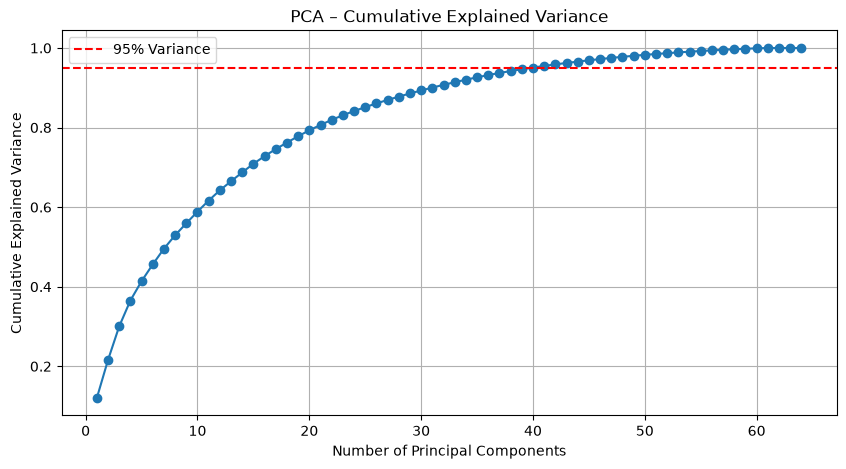

In [249]:
plt.figure(figsize=(10, 5))

plt.plot(range(1, len(explained_variance) + 1),cumulative_variance,marker='o')

plt.axhline(y=0.95, color='red', linestyle='--', label='95% Variance')

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA – Cumulative Explained Variance')
plt.legend()
plt.grid()
plt.show()

In [250]:
# Determine the number of components for 95% variance
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Components required for 95% variance:", n_components)

Components required for 95% variance: 40


In [251]:
print("First 10 explained variance ratios:")
print(explained_variance[:10])

print("\nFirst 10 cumulative values:")
print(cumulative_variance[:10])

print("\nTotal explained variance:")
print(explained_variance.sum())

First 10 explained variance ratios:
[0.12033916 0.09561054 0.08444415 0.06498408 0.04860155 0.0421412
 0.03942083 0.03389381 0.02998221 0.02932003]

First 10 cumulative values:
[0.12033916 0.21594971 0.30039385 0.36537793 0.41397948 0.45612068
 0.49554151 0.52943532 0.55941753 0.58873755]

Total explained variance:
1.0


In [252]:
print("Original X shape:", X.shape)
print("Standardized X shape:", X_scaled_features.shape)
print("PCA components:", pca.n_components_)
print("PCA input shape:", pca.n_features_in_)

Original X shape: (1797, 64)
Standardized X shape: (1797, 64)
PCA components: 64
PCA input shape: 64


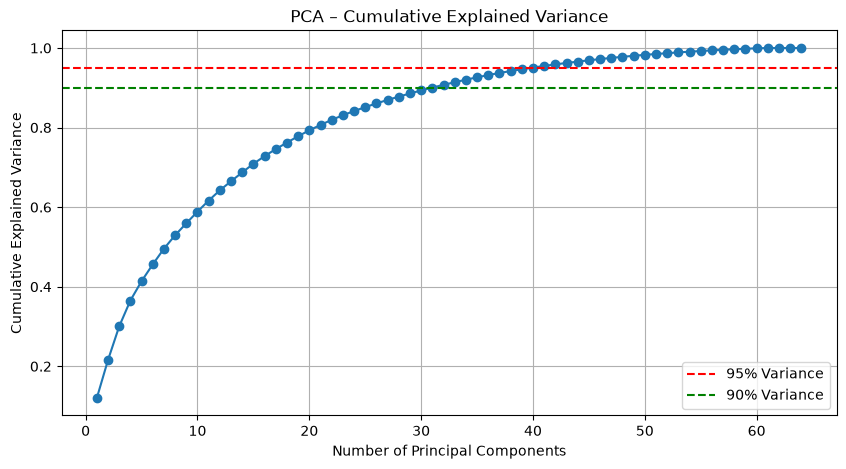

In [253]:
# cumulative variance plot
plt.figure(figsize=(10, 5))

plt.plot(range(1, len(cumulative_variance) + 1),cumulative_variance,marker='o')

plt.axhline(0.95, color='red', linestyle='--', label='95% Variance')
plt.axhline(0.90, color='green', linestyle='--', label='90% Variance')

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA – Cumulative Explained Variance')
plt.legend()
plt.grid()
plt.show()

In [254]:
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Components for 90% variance:", n_90)
print("Components for 95% variance:", n_95)

Components for 90% variance: 31
Components for 95% variance: 40


In [255]:
# fit final pca
pca_final = PCA(n_components=n_95)

X_pca_final = pca_final.fit_transform(X_scaled_features)

In [256]:
print("Original shape:", X.shape)
print("Reduced shape:", X_pca_final.shape)
print("Retained variance:", pca_final.explained_variance_ratio_.sum())

Original shape: (1797, 64)
Reduced shape: (1797, 40)
Retained variance: 0.9507791125066468


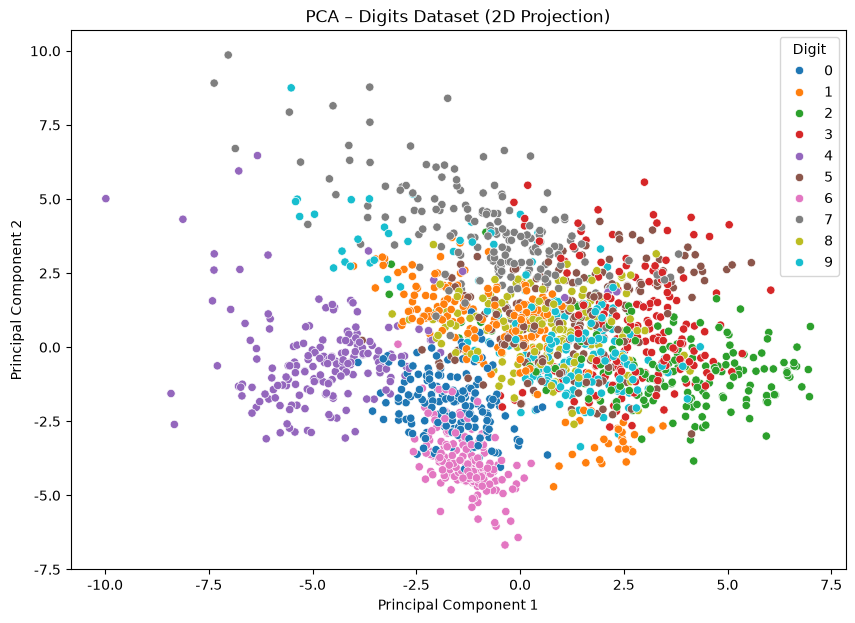

In [257]:
pca_2d = PCA(n_components=2)

X_pca_2d = pca_2d.fit_transform(X_scaled_features)

pca_plot_df = pd.DataFrame(X_pca_2d,columns=['PC1', 'PC2'])

pca_plot_df['Digit'] = y

plt.figure(figsize=(10, 7))

sns.scatterplot(data=pca_plot_df,x='PC1',y='PC2',hue='Digit',palette='tab10',legend='full')

plt.title('PCA – Digits Dataset (2D Projection)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Digit')
plt.show()

### Conclusion

PCA was successfully applied to the Digits dataset to reduce its dimensionality from 64 features to 40 principal components.

The final model retained **95.08% of the total variance**, reducing the feature space by 37.5% while preserving most of the information in the original dataset.

This demonstrates how PCA can simplify high-dimensional datasets, reduce computational complexity, and support visualization while minimizing information loss.

### Generate data

In [258]:
data = {
    'Height': [170, 165, 180, 175, 160, 172, 168, 177, 162, 158],
    'Weight': [65, 59, 75, 68, 55, 70, 62, 74, 58, 54],
    'Age': [30, 25, 35, 28, 22, 32, 27, 33, 24, 21],
    'Gender': [1, 0, 1, 1, 0, 1, 0, 1, 0, 0]  # 1 = Male, 0 = Female
}
data_df = pd.DataFrame(data)
data_df

,Height,Weight,Age,Gender
0,170,65,30,1
1,165,59,25,0
2,180,75,35,1
3,175,68,28,1
4,160,55,22,0
5,172,70,32,1
6,168,62,27,0
7,177,74,33,1
8,162,58,24,0
9,158,54,21,0


In [259]:
# standardize
X = data_df.drop('Gender', axis=1)
y = data_df['Gender']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

# standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_test_scaled = scaler.transform(X_test)

In [260]:
# PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_scaled)
X_test_pca = pca.transform(X_test_scaled)

model = LogisticRegression()
model.fit(X_train_pca, y_train)

y_pred = model.predict(X_test_pca)

ValueError: Found input variables with inconsistent numbers of samples: [10, 8]

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Separate features and target
X = data_df.drop('Gender', axis=1)
y = data_df['Gender']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Apply PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Train model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_pca, y_train)

# Predict
y_pred = model.predict(X_test_pca)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

In [ ]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_scaled)
X_test_pca = pca.transform(X_test_scaled)

model = LogisticRegression()

model.fit(X_train_pca, y_train)

y_pred = model.predict(X_test_pca)

In [ ]:
print("X:", X.shape)
print("y:", y.shape)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

In [ ]:
# PCA 
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.3, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [ ]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Female', 'Male'], yticklabels=['Female', 'Male'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# Prepare data for visualization
scaler_viz = StandardScaler()
X_scaled_viz = scaler_viz.fit_transform(X)

pca_viz = PCA(n_components=2)
X_pca_viz = pca_viz.fit_transform(X_scaled_viz)

y_numeric = pd.factorize(y)[0]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(
    X_scaled_viz[:, 0], X_scaled_viz[:, 1],
    c=y_numeric, cmap='coolwarm', edgecolor='k', s=80
)
plt.xlabel('Original Feature 1')
plt.ylabel('Original Feature 2')
plt.title('Before PCA: Using First 2 Standardized Features')
plt.colorbar(label='Target classes')

plt.subplot(1, 2, 2)
plt.scatter(
    X_pca_viz[:, 0], X_pca_viz[:, 1],
    c=y_numeric, cmap='coolwarm', edgecolor='k', s=80
)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('After PCA: Projected onto 2 Principal Components')
plt.colorbar(label='Target classes')

plt.tight_layout()
plt.show()